# IPL Cricket Data Analysis (2008 to 2024)

Cricket is the sport I follow most, so I wanted to test some common beliefs with real data instead of opinions.

**Questions I want to answer**
1. How much has T20 scoring changed since 2008?
2. Which phase of the innings has changed the most: powerplay, middle overs or death overs?
3. Does winning the toss actually help you win the match? Is chasing better than batting first?
4. Which teams have been the most successful?
5. Who are the all-time top run scorers and wicket takers in the IPL?
6. Is Chepauk really a fortress for Chennai Super Kings?

**Data:** match and ball-by-ball records of every IPL match from 2008 to 2024 (1,095 matches, about 260,000 deliveries). Original source: Cricsheet via the Kaggle "IPL Complete Dataset". See the README for credits.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid", context="notebook")
NAVY, ORANGE, GREY = "#1d2b64", "#e4572e", "#8a93b5"
os.makedirs("charts", exist_ok=True)

def clean_strings(df):
    df.columns = df.columns.str.strip()
    for c in df.columns:
        if pd.api.types.is_string_dtype(df[c]):
            df[c] = df[c].str.strip()
    return df

matches = clean_strings(pd.read_csv("data/matches_2008-2024.csv")).rename(columns={"id": "match_id"})
balls = clean_strings(pd.read_csv("data/deliveries_2008-2024.csv.gz"))

# Teams that changed name are merged into one franchise
TEAM_FIX = {
    "Delhi Daredevils": "Delhi Capitals",
    "Kings XI Punjab": "Punjab Kings",
    "Royal Challengers Bangalore": "Royal Challengers Bengaluru",
    "Rising Pune Supergiants": "Rising Pune Supergiant",
}
for col in ["team1", "team2", "toss_winner", "winner"]:
    matches[col] = matches[col].replace(TEAM_FIX)
for col in ["batting_team", "bowling_team"]:
    balls[col] = balls[col].replace(TEAM_FIX)

balls = balls[balls["inning"] <= 2]                      # innings 3+ are super overs
balls = balls.merge(matches[["match_id", "season"]], on="match_id")
balls["legal"] = ~balls["extras_type"].isin(["wides", "noballs"])

print(f"Matches: {len(matches)}   Deliveries (excluding super overs): {len(balls):,}")
print(f"Seasons: {matches.season.min()} to {matches.season.max()}")

Matches: 1095   Deliveries (excluding super overs): 260,759
Seasons: 2008 to 2024


## 1. How much has scoring changed?
I look at the average first-innings total and the number of sixes per match in each season.

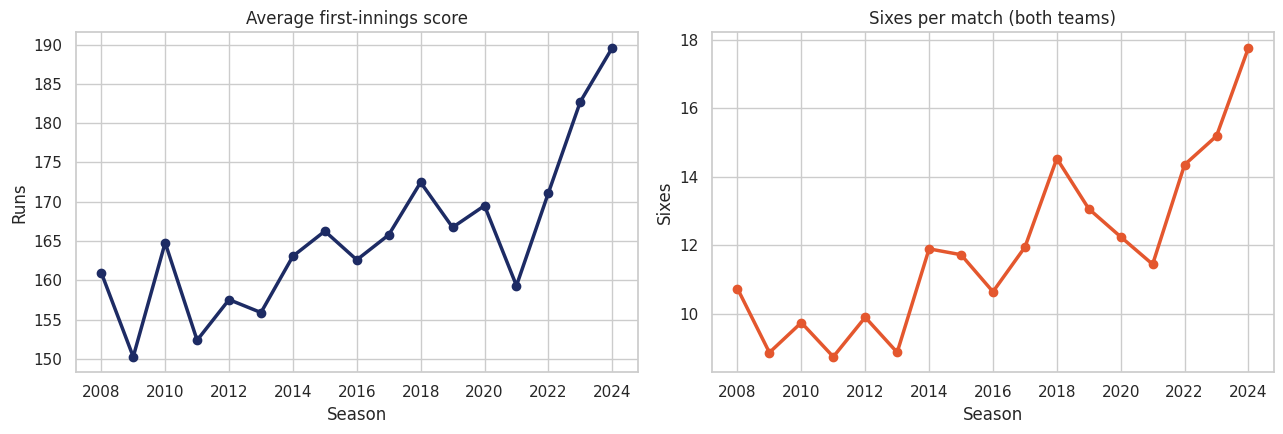

Avg first-innings score: 161 in 2008 -> 190 in 2024 (+29 runs)
Sixes per match: 10.7 in 2008 -> 17.8 in 2024
Average of 2008-2022: 163  vs  2023-2024: 186


In [2]:
inn = balls.groupby(["season", "match_id", "inning"]).total_runs.sum().reset_index()
first_inn = inn[inn.inning == 1].groupby("season").total_runs.mean()
sixes = balls[balls.batsman_runs == 6].groupby("season").size() / matches.groupby("season").size()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(first_inn.index, first_inn.values, marker="o", color=NAVY, lw=2.5)
ax[0].set_title("Average first-innings score")
ax[0].set_ylabel("Runs")
ax[1].plot(sixes.index, sixes.values, marker="o", color=ORANGE, lw=2.5)
ax[1].set_title("Sixes per match (both teams)")
ax[1].set_ylabel("Sixes")
for a in ax: a.set_xlabel("Season")
plt.tight_layout(); plt.savefig("charts/01_scoring_trend.png", dpi=150); plt.show()

print(f"Avg first-innings score: {first_inn[2008]:.0f} in 2008 -> {first_inn[2024]:.0f} in 2024 ({first_inn[2024]-first_inn[2008]:+.0f} runs)")
print(f"Sixes per match: {sixes[2008]:.1f} in 2008 -> {sixes[2024]:.1f} in 2024")
print(f"Average of 2008-2022: {first_inn.loc[2008:2022].mean():.0f}  vs  2023-2024: {first_inn.loc[2023:2024].mean():.0f}")

## 2. Which phase of the innings changed the most?
Powerplay = overs 1 to 6, middle = overs 7 to 15, death = overs 16 to 20. Run rate is runs per legal over.

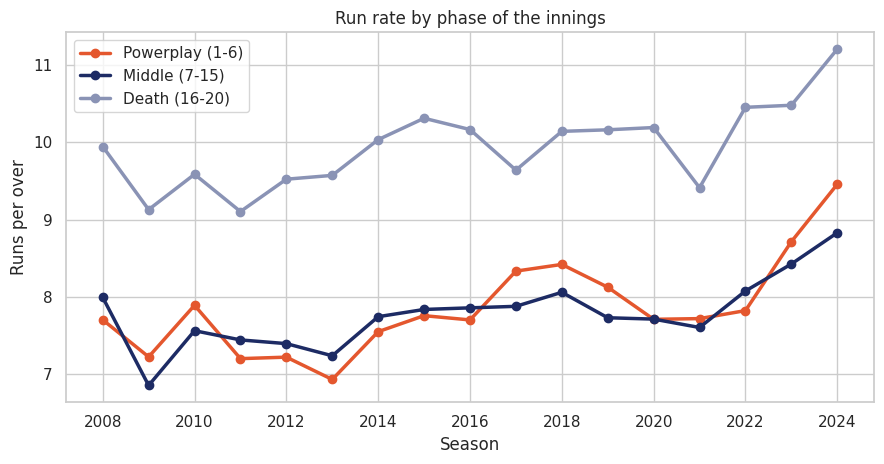

Change in run rate, 2008 -> 2024:
phase
Powerplay (1-6)    1.75
Middle (7-15)      0.84
Death (16-20)      1.26

2008-2022 average vs 2024:
                 2008-2022   2024
phase                            
Powerplay (1-6)       7.69   9.46
Middle (7-15)         7.67   8.83
Death (16-20)         9.83  11.21


In [3]:
balls["phase"] = pd.cut(balls["over"], [-1, 5, 14, 19], labels=["Powerplay (1-6)", "Middle (7-15)", "Death (16-20)"])
runs = balls.groupby(["season", "phase"], observed=True).total_runs.sum()
overs = balls[balls.legal].groupby(["season", "phase"], observed=True).size() / 6
rr = (runs / overs).unstack()

fig, ax = plt.subplots(figsize=(9, 4.8))
for col, color in zip(rr.columns, [ORANGE, NAVY, GREY]):
    ax.plot(rr.index, rr[col], marker="o", lw=2.5, label=col, color=color)
ax.set_title("Run rate by phase of the innings")
ax.set_xlabel("Season"); ax.set_ylabel("Runs per over"); ax.legend()
plt.tight_layout(); plt.savefig("charts/02_phase_run_rate.png", dpi=150); plt.show()

change = (rr.loc[2024] - rr.loc[2008]).round(2)
print("Change in run rate, 2008 -> 2024:"); print(change.to_string())
print()
print("2008-2022 average vs 2024:")
print(pd.DataFrame({"2008-2022": rr.loc[2008:2022].mean().round(2), "2024": rr.loc[2024].round(2)}).to_string())

## 3. Does the toss matter? Is chasing better?

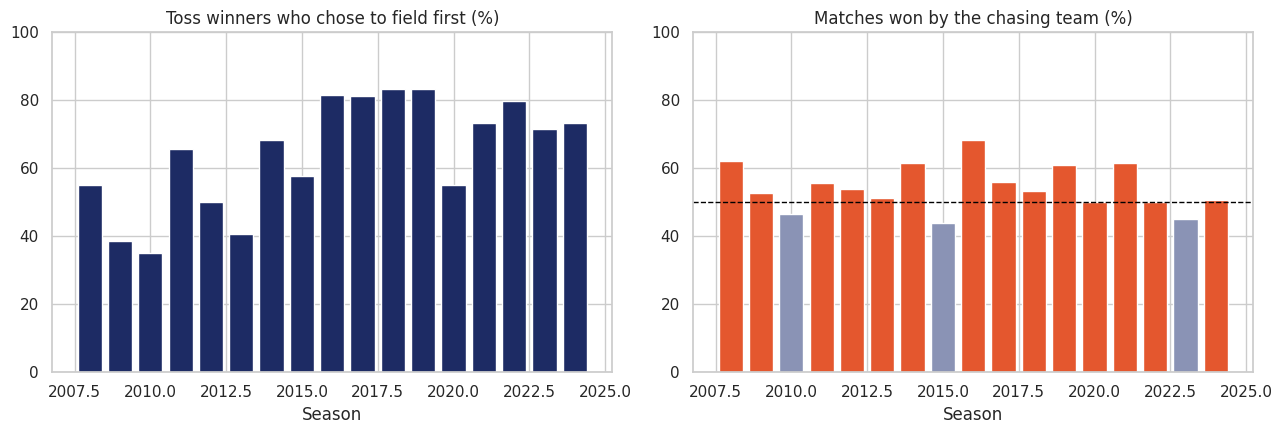

Decided matches: 1090
Toss winner won the match: 50.8%
Chasing team won the match: 54.1%
Toss winners choosing to field: 43% (2008-2010) -> 75% (2022-2024)
Seasons where chasing teams won more than half: 12 of 17


In [4]:
decided = matches[matches.winner.notna()].copy()
decided["toss_winner_won"] = decided.toss_winner == decided.winner
decided["chasing_team_won"] = (
    ((decided.toss_decision == "field") & (decided.toss_winner == decided.winner)) |
    ((decided.toss_decision == "bat") & (decided.toss_winner != decided.winner))
)
field_share = matches.groupby("season").apply(lambda x: (x.toss_decision == "field").mean(), include_groups=False) * 100
chase_win = decided.groupby("season").chasing_team_won.mean() * 100

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].bar(field_share.index, field_share.values, color=NAVY)
ax[0].set_title("Toss winners who chose to field first (%)"); ax[0].set_xlabel("Season"); ax[0].set_ylim(0, 100)
ax[1].bar(chase_win.index, chase_win.values, color=[ORANGE if v >= 50 else GREY for v in chase_win.values])
ax[1].axhline(50, color="black", lw=1, ls="--")
ax[1].set_title("Matches won by the chasing team (%)"); ax[1].set_xlabel("Season"); ax[1].set_ylim(0, 100)
plt.tight_layout(); plt.savefig("charts/03_toss_and_chasing.png", dpi=150); plt.show()

print(f"Decided matches: {len(decided)}")
print(f"Toss winner won the match: {decided.toss_winner_won.mean()*100:.1f}%")
print(f"Chasing team won the match: {decided.chasing_team_won.mean()*100:.1f}%")
print(f"Toss winners choosing to field: {field_share.loc[2008:2010].mean():.0f}% (2008-2010) -> {field_share.loc[2022:2024].mean():.0f}% (2022-2024)")
print(f"Seasons where chasing teams won more than half: {(chase_win > 50).sum()} of {len(chase_win)}")

## 4. Most successful teams
Win percentage of every franchise with at least 50 matches, and the number of IPL titles (winner of the Final).

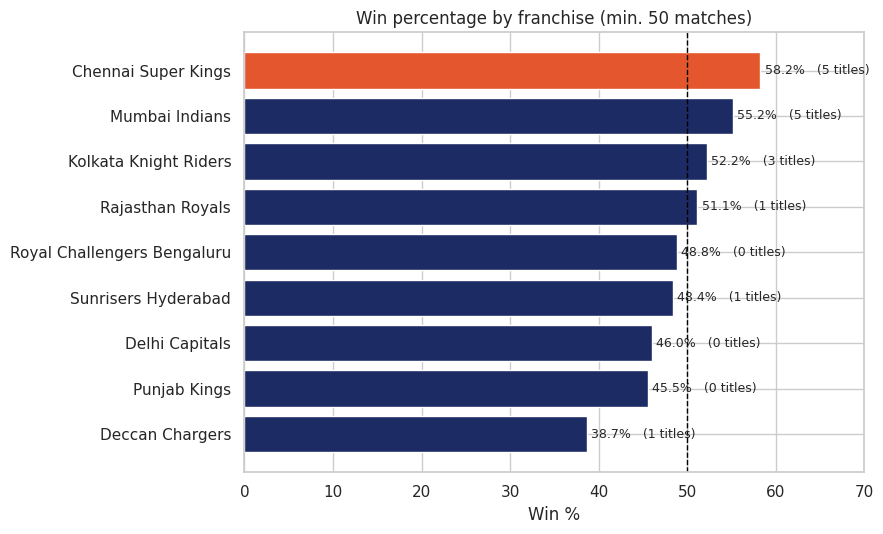

                             matches  wins  win_pct  titles
team                                                       
Chennai Super Kings              237   138     58.2       5
Mumbai Indians                   261   144     55.2       5
Kolkata Knight Riders            251   131     52.2       3
Rajasthan Royals                 219   112     51.1       1
Royal Challengers Bengaluru      252   123     48.8       0
Sunrisers Hyderabad              182    88     48.4       1
Delhi Capitals                   250   115     46.0       0
Punjab Kings                     246   112     45.5       0
Deccan Chargers                   75    29     38.7       1


In [5]:
played = pd.concat([matches[["match_id", "team1"]].rename(columns={"team1": "team"}),
                    matches[["match_id", "team2"]].rename(columns={"team2": "team"})])
played = played.merge(matches[["match_id", "winner"]], on="match_id")
played = played[played.winner.notna()]
tbl = played.groupby("team").agg(matches=("match_id", "count"), wins=("winner", lambda s: 0))
tbl["wins"] = matches.groupby("winner").size().reindex(tbl.index).fillna(0).astype(int)
tbl["win_pct"] = tbl.wins / tbl.matches * 100
titles = matches[matches.match_type == "Final"].groupby("winner").size()
tbl["titles"] = titles.reindex(tbl.index).fillna(0).astype(int)
tbl = tbl[tbl.matches >= 50].sort_values("win_pct")

fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.barh(tbl.index, tbl.win_pct, color=[ORANGE if t == "Chennai Super Kings" else NAVY for t in tbl.index])
for b, (_, r) in zip(bars, tbl.iterrows()):
    ax.text(b.get_width() + 0.5, b.get_y() + b.get_height()/2, f"{r.win_pct:.1f}%   ({int(r.titles)} titles)", va="center", fontsize=9)
ax.set_xlim(0, 70); ax.axvline(50, color="black", lw=1, ls="--")
ax.set_title("Win percentage by franchise (min. 50 matches)"); ax.set_xlabel("Win %")
plt.tight_layout(); plt.savefig("charts/04_team_win_pct.png", dpi=150); plt.show()
print(tbl.sort_values("win_pct", ascending=False)[["matches", "wins", "win_pct", "titles"]].round(1).to_string())

## 5. All-time top run scorers and wicket takers
Wicket counts exclude run outs and retirements, because those are not credited to the bowler.

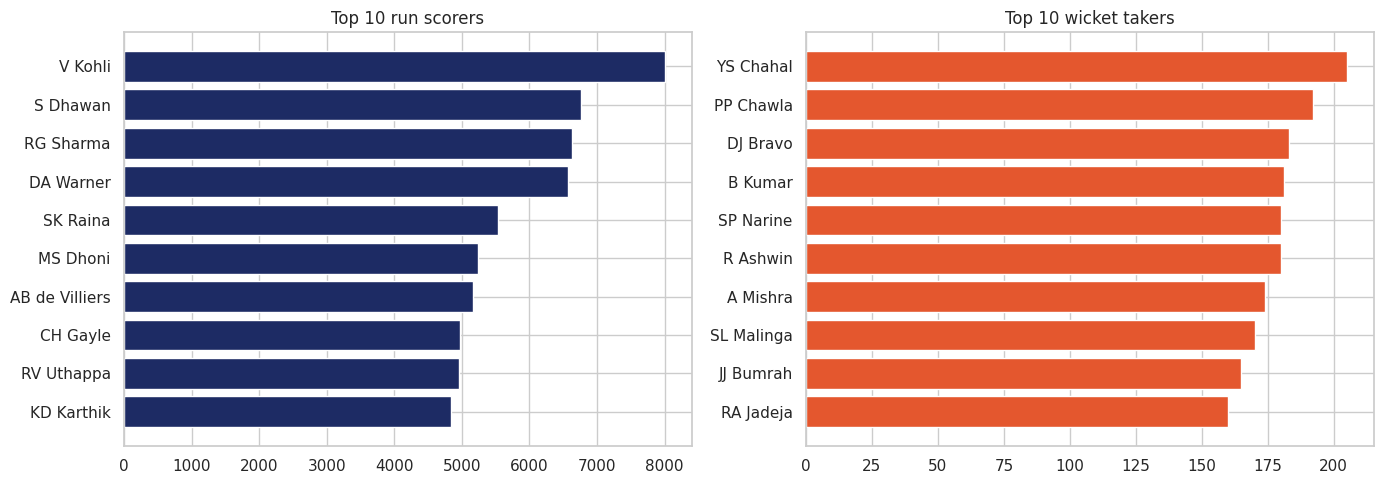

                runs  balls  strike_rate
batter                                  
V Kohli         8004   6065        132.0
S Dhawan        6769   5324        127.1
RG Sharma       6628   5054        131.1
DA Warner       6565   4697        139.8
SK Raina        5528   4043        136.7
MS Dhoni        5243   3812        137.5
AB de Villiers  5162   3403        151.7
CH Gayle        4965   3333        149.0
RV Uthappa      4952   3799        130.4
KD Karthik      4842   3577        135.4

bowler
YS Chahal     205
PP Chawla     192
DJ Bravo      183
B Kumar       181
SP Narine     180
R Ashwin      180
A Mishra      174
SL Malinga    170
JJ Bumrah     165
RA Jadeja     160


In [6]:
bat = balls.groupby("batter").agg(runs=("batsman_runs", "sum"))
faced = balls[balls.extras_type != "wides"].groupby("batter").size()
bat["balls"] = faced
bat["strike_rate"] = bat.runs / bat.balls * 100
top_bat = bat.sort_values("runs", ascending=False).head(10)

not_bowler = ["run out", "retired hurt", "retired out", "obstructing the field"]
wk = balls[(balls.is_wicket == 1) & (~balls.dismissal_kind.isin(not_bowler))].groupby("bowler").size()
top_wk = wk.sort_values(ascending=False).head(10)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].barh(top_bat.index[::-1], top_bat.runs[::-1], color=NAVY)
ax[0].set_title("Top 10 run scorers")
ax[1].barh(top_wk.index[::-1], top_wk.values[::-1], color=ORANGE)
ax[1].set_title("Top 10 wicket takers")
plt.tight_layout(); plt.savefig("charts/05_top_players.png", dpi=150); plt.show()

print(top_bat.round(1).to_string()); print(); print(top_wk.to_string())

## 6. Is Chepauk a fortress for Chennai Super Kings?
I compare CSK's win percentage at Chepauk with their win percentage everywhere else, and check whether batting first or chasing works better at Chepauk.

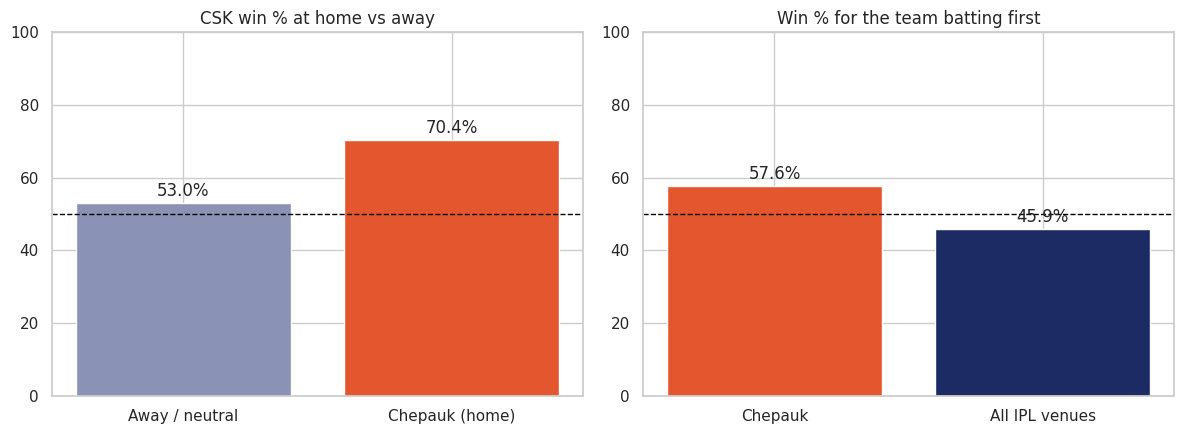

                count  sum  mean
Away / neutral    166   88  53.0
Chepauk (home)     71   50  70.4
Chepauk matches with a result: 85
Team batting first wins at Chepauk: 57.6%  vs all venues: 45.9%
Average first-innings score at Chepauk: 164  vs all venues: 166


In [7]:
csk = matches[((matches.team1 == "Chennai Super Kings") | (matches.team2 == "Chennai Super Kings")) & matches.winner.notna()].copy()
csk["home"] = csk.venue.str.contains("Chidambaram", na=False)
csk["won"] = csk.winner == "Chennai Super Kings"
home_away = csk.groupby("home").won.agg(["count", "sum", "mean"])
home_away.index = ["Away / neutral", "Chepauk (home)"]
home_away["mean"] *= 100

chepauk = decided[decided.venue.str.contains("Chidambaram", na=False)]
bat_first_win = (1 - chepauk.chasing_team_won.mean()) * 100
everywhere_bat_first = (1 - decided.chasing_team_won.mean()) * 100

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].bar(home_away.index, home_away["mean"], color=[GREY, ORANGE])
ax[0].axhline(50, color="black", lw=1, ls="--"); ax[0].set_ylim(0, 100)
ax[0].set_title("CSK win % at home vs away")
for i, v in enumerate(home_away["mean"]): ax[0].text(i, v + 2, f"{v:.1f}%", ha="center")
ax[1].bar(["Chepauk", "All IPL venues"], [bat_first_win, everywhere_bat_first], color=[ORANGE, NAVY])
ax[1].axhline(50, color="black", lw=1, ls="--"); ax[1].set_ylim(0, 100)
ax[1].set_title("Win % for the team batting first")
for i, v in enumerate([bat_first_win, everywhere_bat_first]): ax[1].text(i, v + 2, f"{v:.1f}%", ha="center")
plt.tight_layout(); plt.savefig("charts/06_chepauk.png", dpi=150); plt.show()

print(home_away.round(1).to_string())
print(f"Chepauk matches with a result: {len(chepauk)}")
print(f"Team batting first wins at Chepauk: {bat_first_win:.1f}%  vs all venues: {everywhere_bat_first:.1f}%")
c_first = inn[(inn.inning == 1) & inn.match_id.isin(chepauk.match_id)].total_runs.mean()
print(f"Average first-innings score at Chepauk: {c_first:.0f}  vs all venues: {inn[inn.inning==1].total_runs.mean():.0f}")